<a href="https://colab.research.google.com/github/Fhrull04/analisis-eksplorasi-data/blob/main/Tugas1_Analisis_Eksplorasi_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 1 - Analisis Eksplorasi Data

Nama: Muhammad Fachruliyadi
NIM: 251061032
Program Studi: Sains Data, Institut Teknologi Bacharuddin Jusuf Habibie

Isi tugas:
1. Ambil data sebanyak 100 sampel.
2. (a) Hitung estimasi titik dan estimasi interval memakai distribusi Z dengan tingkat kesalahan 5%.
3. (b) Lakukan resampling dengan jackknife dan bootstrapping, lalu hitung rata-rata hasil resampling. Bootstrapping dijalankan 1000 iterasi.

## Langkah 0. Siapkan library

Kita butuh numpy untuk hitungan, pandas untuk tabel data, scipy untuk nilai kritis distribusi Z, dan matplotlib untuk grafik. Semuanya sudah ada di Google Colab, jadi tidak perlu install apa pun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

np.random.seed(42)

## Langkah 1. Ambil data 100 sampel

Soal meminta data sebanyak 100 sampel. Di sini dipakai dataset `tips` dari seaborn (data tagihan restoran, total 244 baris). Dari situ kita ambil 100 baris secara acak, lalu fokus ke kolom `total_bill` (total tagihan dalam dolar) sebagai variabel yang dianalisis.

Kalau dosen meminta data lain, cukup ganti bagian pembacaan data ini, misalnya dengan `pd.read_csv("namafile.csv")`. Langkah-langkah di bawahnya tetap sama.

In [2]:
df = sns.load_dataset("tips")
sampel = df.sample(n=100, random_state=42).reset_index(drop=True)

data = sampel["total_bill"].values
print("Jumlah sampel:", len(data))
sampel[["total_bill"]].head()

Jumlah sampel: 100


,total_bill
0,19.82
1,8.77
2,24.55
3,25.89
4,13.00


In [3]:
sampel["total_bill"].describe()

,total_bill
count,100.000000
mean,19.272100
std,8.617423
min,3.070000
25%,13.250000
50%,17.815000
75%,23.977500
max,48.170000


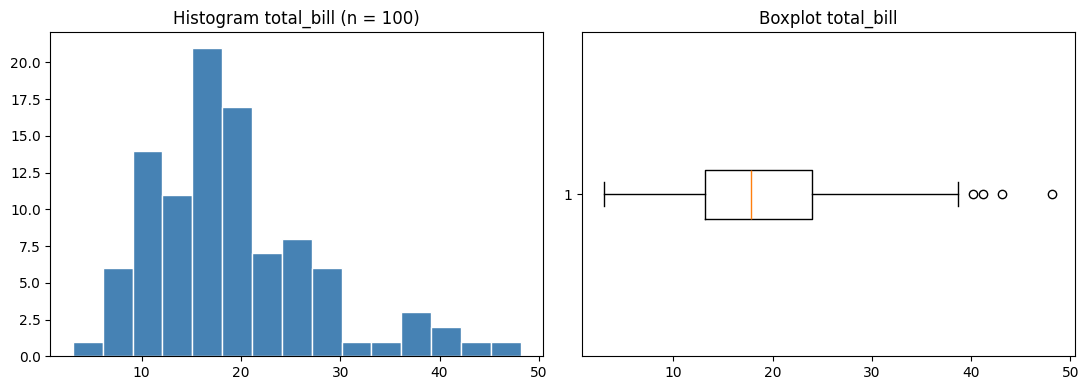

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(data, bins=15, color="steelblue", edgecolor="white")
ax[0].set_title("Histogram total_bill (n = 100)")
ax[1].boxplot(data, vert=False)
ax[1].set_title("Boxplot total_bill")
plt.tight_layout()
plt.show()

Histogramnya sedikit miring ke kanan, wajar untuk data tagihan. Dengan n = 100, teorema limit pusat sudah cukup membuat rata-rata sampel mendekati normal, jadi pemakaian distribusi Z masih layak.

## Langkah 2 (a). Estimasi titik dan estimasi interval dengan distribusi Z

Estimasi titik untuk rata-rata populasi adalah rata-rata sampel:

x̄ = (x1 + x2 + ... + xn) / n

Estimasi interval (selang kepercayaan) untuk rata-rata:

x̄ ± Z(α/2) × (s / √n)

Keterangan:
- tingkat kesalahan α = 5% = 0,05, sehingga tingkat kepercayaan 95%
- Z(α/2) = Z(0,025) = 1,96
- s adalah simpangan baku sampel. Simpangan baku populasi biasanya tidak diketahui, jadi dipakai s sebagai pendekatan. Ini wajar karena n = 100 sudah besar.
- s/√n disebut standard error

In [5]:
n = len(data)
alpha = 0.05

x_bar = data.mean()              # estimasi titik
s = data.std(ddof=1)             # simpangan baku sampel (pembagi n-1)
se = s / np.sqrt(n)              # standard error
z_kritis = stats.norm.ppf(1 - alpha/2)

margin = z_kritis * se
batas_bawah = x_bar - margin
batas_atas = x_bar + margin

print(f"Rata-rata sampel (estimasi titik) : {x_bar:.4f}")
print(f"Simpangan baku sampel (s)         : {s:.4f}")
print(f"Standard error                    : {se:.4f}")
print(f"Z kritis (alpha/2 = 0.025)        : {z_kritis:.4f}")
print(f"Margin of error                   : {margin:.4f}")
print(f"Interval kepercayaan 95%          : ({batas_bawah:.4f} ; {batas_atas:.4f})")

Rata-rata sampel (estimasi titik) : 19.2721
Simpangan baku sampel (s)         : 8.6174
Standard error                    : 0.8617
Z kritis (alpha/2 = 0.025)        : 1.9600
Margin of error                   : 1.6890
Interval kepercayaan 95%          : (17.5831 ; 20.9611)


Cara membaca hasilnya: kita 95% yakin rata-rata total tagihan seluruh populasi berada di antara batas bawah dan batas atas di atas. Estimasi titiknya adalah nilai rata-rata sampel itu sendiri.

## Langkah 3 (b). Resampling

Resampling dipakai untuk menaksir sebaran statistik (di sini rata-rata) tanpa banyak asumsi tentang distribusi data. Ada dua metode yang diminta.

### Jackknife

Idenya: dari 100 data, buang satu data, hitung rata-ratanya, lalu ulangi sampai setiap data pernah dibuang satu kali. Hasilnya 100 rata-rata jackknife.

Rumus yang dipakai:
- rata-rata jackknife = rata-rata dari semua x̄(-i)
- standard error jackknife = √[ (n-1)/n × Σ (x̄(-i) - rata-rata jackknife)² ]

In [6]:
jack_means = np.array([np.delete(data, i).mean() for i in range(n)])

jack_mean = jack_means.mean()
jack_se = np.sqrt((n - 1) / n * np.sum((jack_means - jack_mean) ** 2))

print("Jumlah resample jackknife   :", len(jack_means))
print(f"Rata-rata hasil jackknife   : {jack_mean:.4f}")
print(f"Standard error jackknife    : {jack_se:.4f}")

Jumlah resample jackknife   : 100
Rata-rata hasil jackknife   : 19.2721
Standard error jackknife    : 0.8617


### Bootstrapping (1000 iterasi)

Idenya: dari 100 data asli, ambil 100 data baru secara acak dengan pengembalian (satu data boleh terambil berkali-kali). Hitung rata-ratanya. Ulangi 1000 kali, sehingga kita punya 1000 rata-rata bootstrap.

In [7]:
B = 1000
boot_means = np.array([
    np.random.choice(data, size=n, replace=True).mean()
    for _ in range(B)
])

boot_mean = boot_means.mean()
boot_se = boot_means.std(ddof=1)
ci_boot = np.percentile(boot_means, [2.5, 97.5])

print("Jumlah iterasi bootstrap    :", B)
print(f"Rata-rata hasil bootstrap   : {boot_mean:.4f}")
print(f"Standard error bootstrap    : {boot_se:.4f}")
print(f"Interval bootstrap 95%      : ({ci_boot[0]:.4f} ; {ci_boot[1]:.4f})")

Jumlah iterasi bootstrap    : 1000
Rata-rata hasil bootstrap   : 19.2564
Standard error bootstrap    : 0.9095
Interval bootstrap 95%      : (17.5135 ; 21.0406)


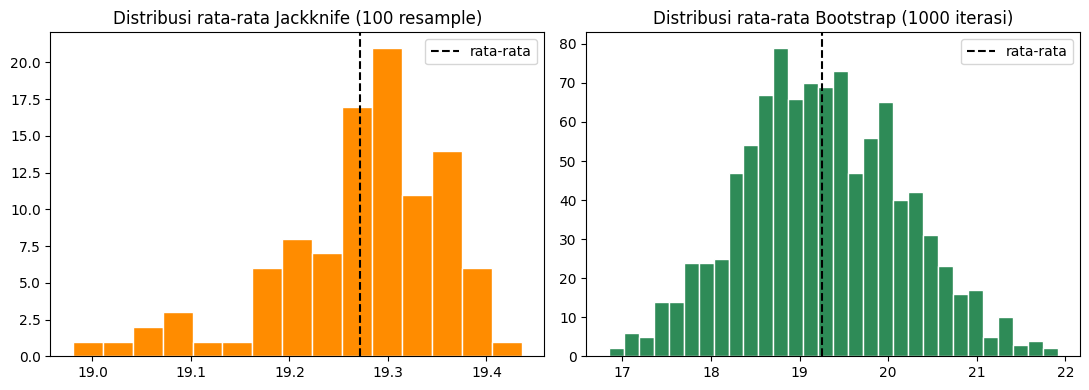

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(jack_means, bins=15, color="darkorange", edgecolor="white")
ax[0].axvline(jack_mean, color="black", linestyle="--", label="rata-rata")
ax[0].set_title("Distribusi rata-rata Jackknife (100 resample)")
ax[0].legend()

ax[1].hist(boot_means, bins=30, color="seagreen", edgecolor="white")
ax[1].axvline(boot_mean, color="black", linestyle="--", label="rata-rata")
ax[1].set_title("Distribusi rata-rata Bootstrap (1000 iterasi)")
ax[1].legend()

plt.tight_layout()
plt.show()

## Langkah 4. Bandingkan semua hasil

In [9]:
hasil = pd.DataFrame({
    "Metode": ["Sampel asli (estimasi titik)", "Jackknife", "Bootstrap (1000x)"],
    "Rata-rata": [x_bar, jack_mean, boot_mean],
    "Standard error": [se, jack_se, boot_se],
})
hasil.round(4)

,Metode,Rata-rata,Standard error
0,Sampel asli (estimasi titik),19.2721,0.8617
1,Jackknife,19.2721,0.8617
2,Bootstrap (1000x),19.2564,0.9095


## Kesimpulan

Rata-rata sampel, rata-rata jackknife, dan rata-rata bootstrap hasilnya sangat berdekatan. Standard error dari ketiga pendekatan juga hampir sama. Ini menunjukkan estimasi rata-rata dari 100 sampel cukup stabil.

Rata-rata jackknife persis sama dengan rata-rata sampel asli, itu memang sifat matematis jackknife untuk statistik rata-rata. Rata-rata bootstrap sedikit berbeda karena prosesnya acak, dan selisihnya mengecil kalau jumlah iterasi dinaikkan.

Interval kepercayaan Z (95%) dan interval persentil bootstrap (95%) juga hampir berimpit, jadi asumsi normal pada metode Z masih masuk akal untuk data ini.